# Projecte: BICITIERRA - Baseline

Per a refinar la forma en què fem les prediccions, anem a fer unes gràfiques que ens mostren visualment com se comporten les dades.

In [5]:
# En primer lloc anem a carregar les llibreries necessàries i llegir el dataset de vendes.

import pandas as pd

df_original = pd.read_csv('../dades/sales_history.csv')

# mostrem les 10 primeres files per una primera inspecció visual
df_original.head(10)


,month,channel,product_line,region,marketing_spend,avg_discount,stock_units,website_sessions,sales_units,revenue,marketing_budget,planned_discount,list_price,campaign,days_in_month,closing_stock_units,stockout
0,2021-01,store,urban,coast,2190.14,0.047,150,3763.0,95,38024.70,2002.85,0.034,420.0,none,31,55,0
1,2021-01,store,urban,inland,3281.92,0.074,88,4664.0,82,31891.44,3016.71,0.062,420.0,none,31,6,0
2,2021-01,store,urban,metro,3347.16,0.050,141,5073.0,141,56259.00,3386.79,0.046,420.0,none,31,0,1
3,2021-01,store,mountain,coast,2530.35,0.037,66,3705.0,56,37210.32,2396.99,0.028,690.0,none,31,10,0
4,2021-01,store,mountain,inland,2136.16,0.101,61,3318.0,44,27293.64,2272.67,0.092,690.0,none,31,17,0
5,2021-01,store,mountain,metro,3566.49,0.011,48,4541.0,48,32755.68,3308.59,0.012,690.0,none,31,0,1
6,2021-01,store,electric,coast,1706.78,0.075,57,2693.0,39,53391.00,1811.32,0.071,1480.0,none,31,18,0
7,2021-01,store,electric,inland,3840.56,0.056,17,4483.0,17,23751.04,3652.61,0.047,1480.0,none,31,0,1
8,2021-01,store,electric,metro,2578.57,0.023,55,3765.0,48,69406.08,2722.88,0.043,1480.0,none,31,7,0
9,2021-01,ecommerce,urban,coast,3067.64,0.045,189,7085.0,130,52143.00,3138.31,0.046,420.0,none,31,59,0


In [6]:
# Anem a separar el mes i l'any, com hem fet en altres exemples
df_original['month_solt'] = df_original['month'].str[5:7].astype(int)
df_original['year_solt'] = df_original['month'].str[0:4].astype(int)
# Ara que ja sabem que la informació que utilitzem en la baseline per a predicció de vendes
# són les mitjanes de les vendes anteriors, podem crear unes quantes columnes amb diferents
# mitjanes, i veure la correlació de cadascuna d'elles amb les vendes

df_original["ch_mean"] = (
    df_original.groupby("channel")["sales_units"]
    .transform("mean")
    .round(2)
)
df_original["pr_mean"] = (
    df_original.groupby("product_line")["sales_units"]
    .transform("mean")
    .round(2)
)
df_original["re_mean"] = (
    df_original.groupby("region")["sales_units"]
    .transform("mean")
    .round(2)
)
df_original["ca_mean"] = (
    df_original.groupby("campaign")["sales_units"]
    .transform("mean")
    .round(2)
)
df_original["ch_pr_mean"] = (
    df_original.groupby(['channel','product_line'])["sales_units"]
    .transform("mean")
    .round(2)
)
df_original["ch_pr_re_mean"] = (
    df_original.groupby(['channel','product_line','region'])["sales_units"]
    .transform("mean")
    .round(2)
)
df_original["ch_pr_re_ca_mean"] = (
    df_original.groupby(['channel','product_line','region','campaign'])["sales_units"]
    .transform("mean")
    .round(2)
)
correlacions = df_original[["sales_units","ch_mean", "pr_mean", "re_mean","ca_mean","ch_pr_mean","ch_pr_re_mean","ch_pr_re_ca_mean"]
].corr()['sales_units']

print(correlacions)

sales_units         1.000000
ch_mean             0.203388
pr_mean             0.691405
re_mean             0.417489
ca_mean             0.253155
ch_pr_mean          0.723938
ch_pr_re_mean       0.847599
ch_pr_re_ca_mean    0.895684
Name: sales_units, dtype: float64


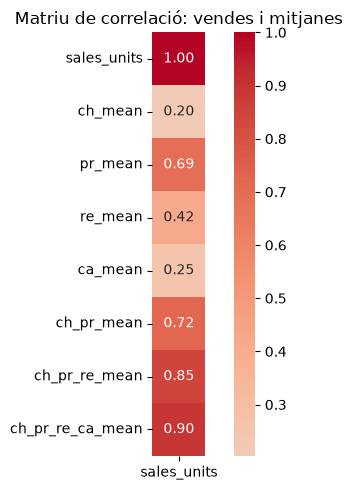

In [7]:
# amb un gràfic
import matplotlib.pyplot as plt
import seaborn as sns

cols_corr = [
    "sales_units",
    "ch_mean",
    "pr_mean",
    "re_mean",
    "ca_mean",
    "ch_pr_mean",
    "ch_pr_re_mean",
    "ch_pr_re_ca_mean"
]

corr = df_original[cols_corr].corr()['sales_units']

plt.figure(figsize=(6, 5))
sns.heatmap(
    corr.to_frame(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)
plt.title("Matriu de correlació: vendes i mitjanes")
plt.tight_layout()
plt.show()

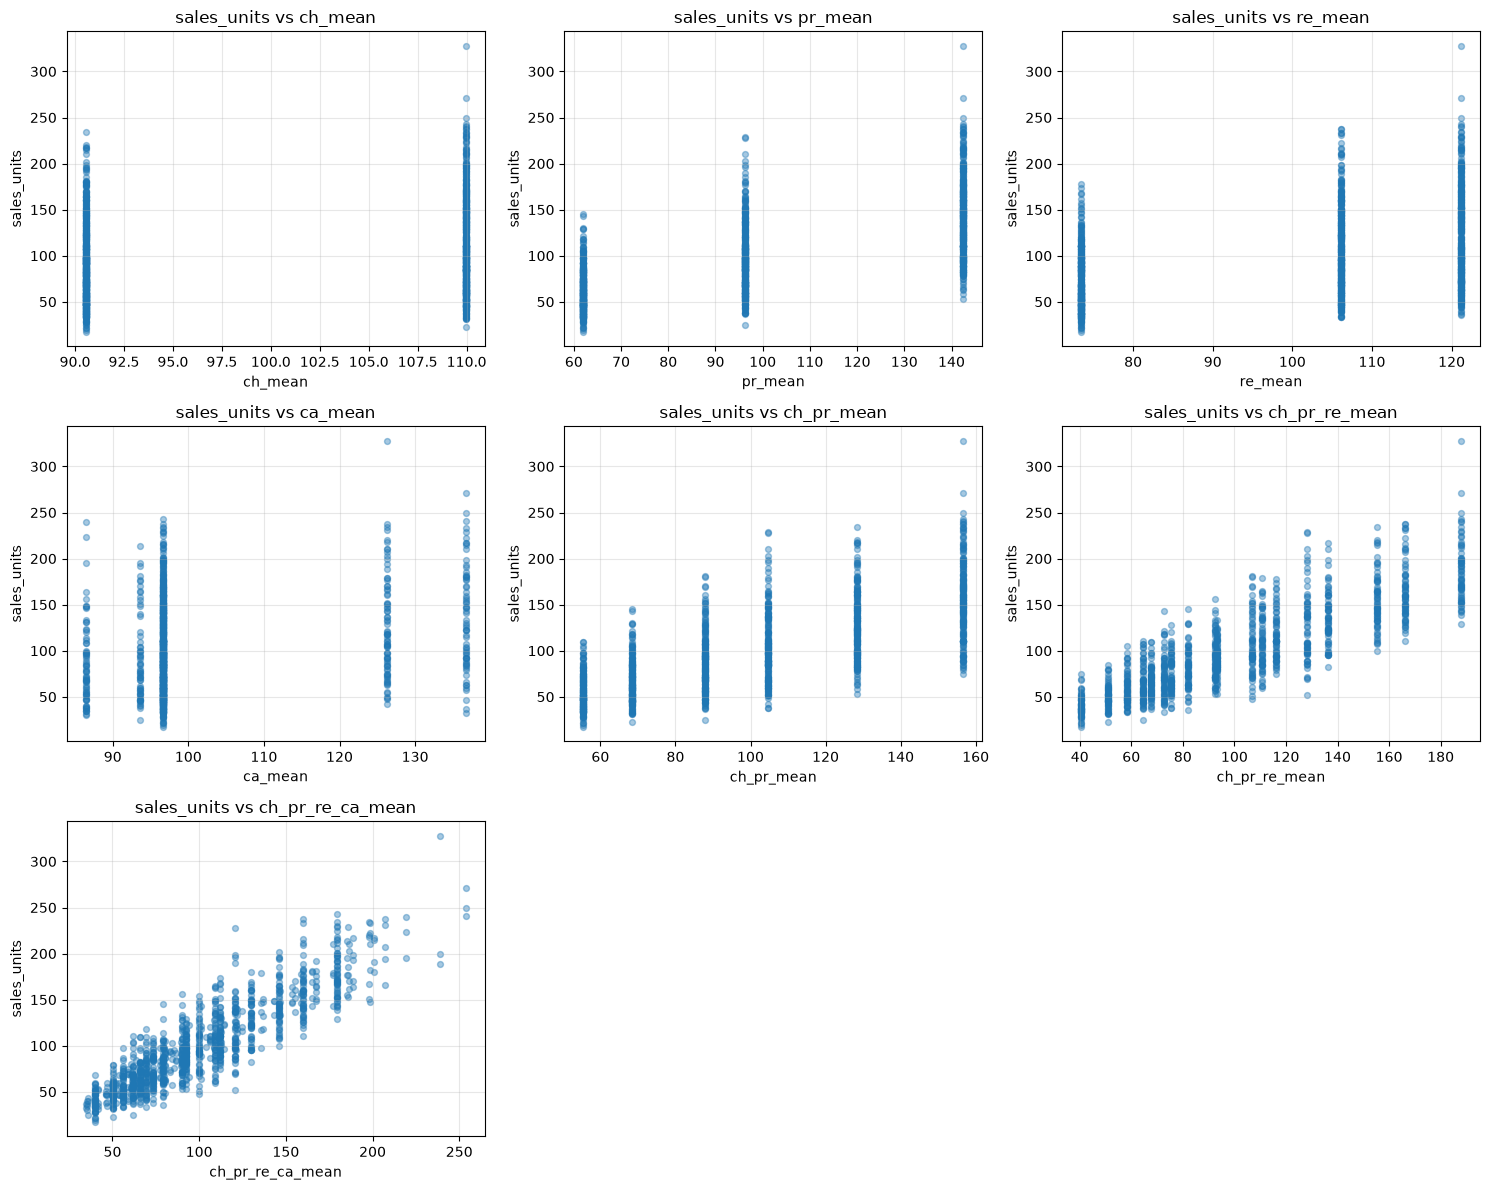

In [8]:
# gràfics de dispersió de les diferents mitjanes respecte als valors reals

mitjanes = [
    "ch_mean", "pr_mean", "re_mean", "ca_mean",
    "ch_pr_mean", "ch_pr_re_mean", "ch_pr_re_ca_mean"
]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for ax, col in zip(axes, mitjanes):
    ax.scatter(df_original[col], df_original["sales_units"], alpha=0.4, s=18)
    ax.set_xlabel(col)
    ax.set_ylabel("sales_units")
    ax.set_title(f"sales_units vs {col}")
    ax.grid(alpha=0.3)

for ax in axes[len(mitjanes):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [9]:
# Evolució de les vendes
# Per saber si és millor acotar les mitjanes als anys més recents o no
resum_any = (
    df_original.groupby(['year_solt'])["sales_units"]
    .sum()
    .round(2)
    .reset_index()
)
resum_any

,year_solt,sales_units
0,2021,19930
1,2022,20753
2,2023,21589
3,2024,21520
4,2025,22420
5,2026,12878


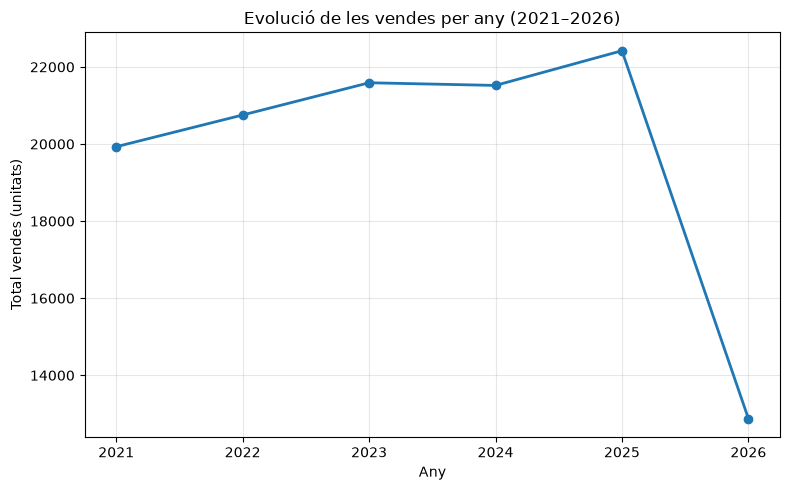

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(
    resum_any["year_solt"],
    resum_any["sales_units"],
    marker="o",
    linewidth=2
)

plt.title("Evolució de les vendes per any (2021–2026)")
plt.xlabel("Any")
plt.ylabel("Total vendes (unitats)")
plt.grid(alpha=0.3)
plt.xticks(resum_any["year_solt"])
plt.tight_layout()
plt.show()

In [11]:
# Evolució de les vendes
# Per saber si és millor acotar les mitjanes als anys més recents o no
resum_any_mes = (
    df_original.groupby(['month'])["sales_units"]
    .sum()
    .round(2)
    .reset_index()
)
resum_any_mes.head(36)

,month,sales_units
0,2021-01,1226
1,2021-02,1383
2,2021-03,1725
3,2021-04,2169
4,2021-05,1769
5,2021-06,1937
6,2021-07,2223
7,2021-08,1649
8,2021-09,1502
9,2021-10,1396


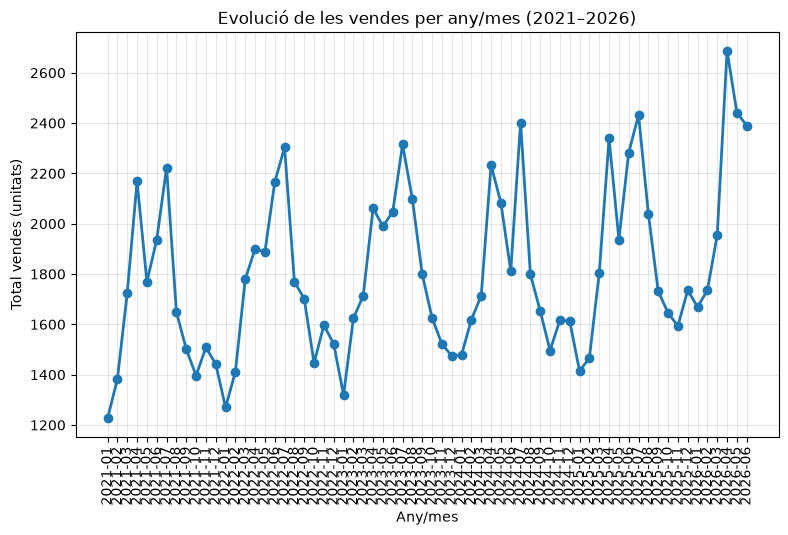

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(
    resum_any_mes['month'],
    resum_any_mes["sales_units"],
    marker="o",
    linewidth=2
)

plt.title("Evolució de les vendes per any/mes (2021–2026)")
plt.xlabel("Any/mes")
plt.ylabel("Total vendes (unitats)")
plt.grid(alpha=0.3)
plt.xticks(resum_any_mes["month"])
plt.tight_layout()
plt.xticks(rotation=90)
plt.show()

Com hem vist que hi ha un patró i hi ha mesos que tots els anys venen més o venen menys, i el patró se repeteix cada any, podem intentar afegir el mes a la baseline i veure què passa

In [13]:
df_entrenament = df_original[df_original['month'] < '2025-01']
df_test=df_original[df_original['month'].str.slice(0,4) == '2025']
group_mean=df_entrenament.groupby(['channel','product_line','region','campaign','month_solt'])['sales_units'].mean().rename('mitjana')
df_test = df_test.merge(group_mean, on=['channel', 'product_line','region','campaign','month_solt'])
df_test['abs_error'] = (df_test['sales_units'] - df_test['mitjana']).abs()
df_test[['month','channel','product_line','region','campaign','sales_units','month_solt','mitjana','abs_error']]


,month,channel,product_line,region,campaign,sales_units,month_solt,mitjana,abs_error
0,2025-01,store,urban,coast,none,100,1,105.500000,5.500000
1,2025-01,store,urban,inland,none,64,1,79.500000,15.500000
2,2025-01,store,urban,metro,none,120,1,125.000000,5.000000
3,2025-01,store,mountain,coast,none,79,1,64.000000,15.000000
4,2025-01,store,mountain,inland,none,37,1,47.750000,10.750000
...,...,...,...,...,...,...,...,...,...
200,2025-12,ecommerce,mountain,inland,christmas,67,12,72.000000,5.000000
201,2025-12,ecommerce,mountain,metro,christmas,131,12,105.000000,26.000000
202,2025-12,ecommerce,electric,coast,christmas,68,12,59.333333,8.666667
203,2025-12,ecommerce,electric,inland,christmas,53,12,39.000000,14.000000


In [14]:
# mirem si millora la mètrica
mae = df_test['abs_error'].mean().round(2)
total_vendes = df_test['sales_units'].sum()
total_dif = df_test['abs_error'].sum()
wape = (100 * (total_dif / total_vendes)).round(2)
print(f"MAE {mae} WAPE {wape}")

MAE 15.62 WAPE 14.97


Hem baixat d'un percentatge de 17,25 a 14,97.
Ara podem pensar que com ja tenim el mes no ens cal la campanya. Anem a provar què passa si repetim el procés sense la campanya.

In [15]:
df_test_ordenat = df_test.sort_values(by='abs_error', ascending=False)
df_test_ordenat[['month','channel','product_line','region','campaign','month_solt','sales_units','mitjana','abs_error']].head(25)

,month,channel,product_line,region,campaign,month_solt,sales_units,mitjana,abs_error
101,2025-06,ecommerce,mountain,metro,none,6,228,144.750000,83.250000
96,2025-06,ecommerce,urban,coast,none,6,237,165.000000,72.000000
117,2025-07,ecommerce,mountain,metro,summer,7,229,171.666667,57.333333
104,2025-06,ecommerce,electric,metro,none,6,129,78.750000,50.250000
68,2025-04,ecommerce,electric,metro,spring,4,129,80.333333,48.666667
63,2025-04,ecommerce,urban,metro,none,4,234,187.500000,46.500000
45,2025-03,ecommerce,urban,coast,none,3,141,186.750000,45.750000
66,2025-04,ecommerce,mountain,metro,spring,4,210,166.000000,44.000000
112,2025-07,ecommerce,urban,coast,summer,7,233,190.250000,42.750000
166,2025-10,ecommerce,urban,metro,none,10,195,153.750000,41.250000


In [16]:
df_test['percentatge_error']=(100*(df_test['abs_error'] / df_test['sales_units'])).round(2)
df_test_ordenat = df_test.sort_values(by='percentatge_error', ascending=False)
df_test_ordenat[['month','channel','product_line','region','campaign','month_solt','sales_units','mitjana','abs_error','percentatge_error']].head(25)

,month,channel,product_line,region,campaign,month_solt,sales_units,mitjana,abs_error,percentatge_error
176,2025-11,store,mountain,inland,none,11,25,43.000000,18.000000,72.00
19,2025-02,store,urban,inland,none,2,53,90.500000,37.500000,70.75
100,2025-06,ecommerce,mountain,inland,none,6,63,96.750000,33.750000,53.57
127,2025-08,store,electric,metro,none,8,50,73.000000,23.000000,46.00
8,2025-01,store,electric,metro,none,1,37,53.500000,16.500000,44.59
44,2025-03,store,electric,metro,none,3,95,54.500000,40.500000,42.63
104,2025-06,ecommerce,electric,metro,none,6,129,78.750000,50.250000,38.95
68,2025-04,ecommerce,electric,metro,spring,4,129,80.333333,48.666667,37.73
134,2025-08,ecommerce,electric,coast,none,8,104,65.750000,38.250000,36.78
101,2025-06,ecommerce,mountain,metro,none,6,228,144.750000,83.250000,36.51


In [17]:
df_entrenament = df_original[df_original['month'] < '2025-01']
df_test=df_original[df_original['month'].str.slice(0,4) == '2025']
group_mean=df_entrenament.groupby(['channel','product_line','region','month_solt'])['sales_units'].mean().rename('mitjana')
df_test = df_test.merge(group_mean, on=['channel', 'product_line','region','month_solt'])
df_test['abs_error'] = (df_test['sales_units'] - df_test['mitjana']).abs()
df_test[['month','channel','product_line','region','month_solt','mitjana','abs_error']]


,month,channel,product_line,region,month_solt,mitjana,abs_error
0,2025-01,store,urban,coast,1,105.50,5.50
1,2025-01,store,urban,inland,1,79.50,15.50
2,2025-01,store,urban,metro,1,125.00,5.00
3,2025-01,store,mountain,coast,1,64.00,15.00
4,2025-01,store,mountain,inland,1,47.75,10.75
...,...,...,...,...,...,...,...
211,2025-12,ecommerce,mountain,inland,12,64.50,2.50
212,2025-12,ecommerce,mountain,metro,12,102.75,28.25
213,2025-12,ecommerce,electric,coast,12,55.00,13.00
214,2025-12,ecommerce,electric,inland,12,39.00,14.00


In [18]:
# mirem si millora la mètrica
mae = df_test['abs_error'].mean().round(2)
total_vendes = df_test['sales_units'].sum()
total_dif = df_test['abs_error'].sum()
wape = (100 * (total_dif / total_vendes)).round(2)
print(f"MAE {mae} WAPE {wape}")

MAE 16.43 WAPE 15.83


Hem pujat de 14,97 a 15,83. Per tant, la millor combinació que hem trobar fins ara és calcular la mitjana agrupant per canal, product_line, regió, campanya i mes de l'any. El repte quan comenceu a fer models de ML és millorar eixe 14,97.